<a href="https://colab.research.google.com/github/aakankshalahane/NLP-Projects-/blob/main/Multilingual_Text_Annotation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install the libraries required for this project

!pip install pandas matplotlib seaborn langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 20.6 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=9ba665a461af163cc12fef03840e74294c40529585df13d60feb5056c9e7d504
  Stored in directory: /root/.cache/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect


In [2]:
# Import the tools we need

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from langdetect import detect, DetectorFactory

# Keep language detection results consistent
DetectorFactory.seed = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
# Create sample sentences in different languages

data = {
    "Text": [
        # English
        "I love this product.",
        "The service is terrible.",
        "The delivery was okay.",

        # German
        "Ich liebe dieses Produkt.",
        "Der Service ist schrecklich.",
        "Die Lieferung war in Ordnung.",

        # French
        "J'aime beaucoup ce produit.",
        "Le service est mauvais.",
        "La livraison est correcte.",

        # Spanish
        "Me encanta este producto.",
        "El servicio es terrible.",
        "La entrega está bien.",

        # Hindi
        "मुझे यह उत्पाद पसंद है।",
        "सेवा बहुत खराब है।",
        "डिलीवरी ठीक थी।"
    ],

    "Expected_Language": [
        "English", "English", "English",
        "German", "German", "German",
        "French", "French", "French",
        "Spanish", "Spanish", "Spanish",
        "Hindi", "Hindi", "Hindi"
    ],

    "Sentiment_Label": [
        "Positive", "Negative", "Neutral",
        "Positive", "Negative", "Neutral",
        "Positive", "Negative", "Neutral",
        "Positive", "Negative", "Neutral",
        "Positive", "Negative", "Neutral"
    ]
}

# Convert our data into a DataFrame
df = pd.DataFrame(data)

# Display the dataset
df

,Text,Expected_Language,Sentiment_Label
0,I love this product.,English,Positive
1,The service is terrible.,English,Negative
2,The delivery was okay.,English,Neutral
3,Ich liebe dieses Produkt.,German,Positive
4,Der Service ist schrecklich.,German,Negative
5,Die Lieferung war in Ordnung.,German,Neutral
6,J'aime beaucoup ce produit.,French,Positive
7,Le service est mauvais.,French,Negative
8,La livraison est correcte.,French,Neutral
9,Me encanta este producto.,Spanish,Positive


In [9]:
# Perform language detection using the langdetect library

# Dictionary to map 2-letter ISO language codes to expected full names
lang_map = {
    'en': 'English',
    'de': 'German',
    'fr': 'French',
    'es': 'Spanish',
    'hi': 'Hindi'
}

# Detect language code and map to full name
def detect_language_name(text):
    try:
        code = detect(text)
        return lang_map.get(code, "Unknown")
    except Exception:
        return "Error"

df["Detected_Language"] = df["Text"].apply(detect_language_name)

# Check whether the detected language matches the expected language
df["Language_Match"] = (
    df["Expected_Language"] == df["Detected_Language"]
)

# Calculate language identification accuracy
language_accuracy = (
    df["Language_Match"].mean() * 100
)

print(
    "Language Detection Accuracy:",
    round(language_accuracy, 2),
    "%"
)

# Display sentences that were not identified correctly
df[df["Language_Match"] == False]

Language Detection Accuracy: 100.0 %


,Text,Expected_Language,Sentiment_Label,Annotation_Category,Detected_Language,Language_Match


In [10]:
# Create a function to assign annotation categories

def assign_category(sentiment):

    if sentiment == "Positive":
        return "Positive Feedback"

    elif sentiment == "Negative":
        return "Negative Feedback"

    else:
        return "Neutral Feedback"


# Apply the annotation function
df["Annotation_Category"] = df["Sentiment_Label"].apply(
    assign_category
)

# Display the updated dataset
df[[
    "Text",
    "Detected_Language",
    "Sentiment_Label",
    "Annotation_Category"
]]

,Text,Detected_Language,Sentiment_Label,Annotation_Category
0,I love this product.,English,Positive,Positive Feedback
1,The service is terrible.,English,Negative,Negative Feedback
2,The delivery was okay.,English,Neutral,Neutral Feedback
3,Ich liebe dieses Produkt.,German,Positive,Positive Feedback
4,Der Service ist schrecklich.,German,Negative,Negative Feedback
5,Die Lieferung war in Ordnung.,German,Neutral,Neutral Feedback
6,J'aime beaucoup ce produit.,French,Positive,Positive Feedback
7,Le service est mauvais.,French,Negative,Negative Feedback
8,La livraison est correcte.,French,Neutral,Neutral Feedback
9,Me encanta este producto.,Spanish,Positive,Positive Feedback


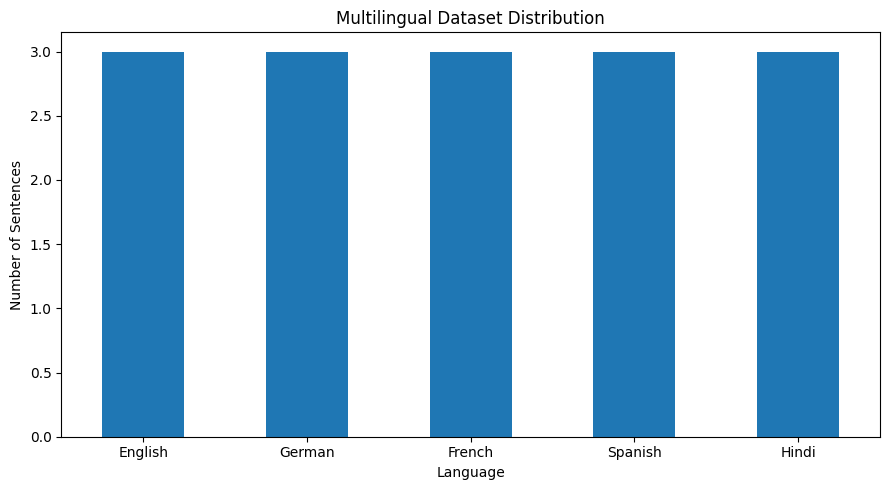

In [11]:
# Count sentences by language

language_summary = df["Detected_Language"].value_counts()

# Create a bar chart
language_summary.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Multilingual Dataset Distribution")
plt.xlabel("Language")
plt.ylabel("Number of Sentences")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

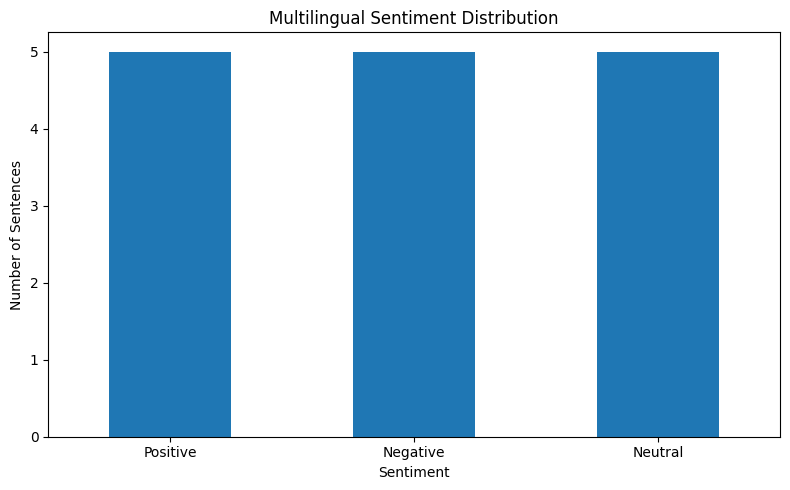

In [12]:
# Count the number of sentences in each sentiment category

sentiment_summary = df["Sentiment_Label"].value_counts()

# Create a chart
sentiment_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Multilingual Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Sentences")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [13]:
# Add columns for human annotation review

df["Human_Review"] = "Pending"

df["Corrected_Language"] = df["Detected_Language"]

df["Corrected_Sentiment"] = df["Sentiment_Label"]

df["Review_Comments"] = ""

# Display the annotation review table

df[[
    "Text",
    "Detected_Language",
    "Sentiment_Label",
    "Human_Review",
    "Corrected_Language",
    "Corrected_Sentiment"
]]

,Text,Detected_Language,Sentiment_Label,Human_Review,Corrected_Language,Corrected_Sentiment
0,I love this product.,English,Positive,Pending,English,Positive
1,The service is terrible.,English,Negative,Pending,English,Negative
2,The delivery was okay.,English,Neutral,Pending,English,Neutral
3,Ich liebe dieses Produkt.,German,Positive,Pending,German,Positive
4,Der Service ist schrecklich.,German,Negative,Pending,German,Negative
5,Die Lieferung war in Ordnung.,German,Neutral,Pending,German,Neutral
6,J'aime beaucoup ce produit.,French,Positive,Pending,French,Positive
7,Le service est mauvais.,French,Negative,Pending,French,Negative
8,La livraison est correcte.,French,Neutral,Pending,French,Neutral
9,Me encanta este producto.,Spanish,Positive,Pending,Spanish,Positive


In [14]:
# Select the first sentence for manual review

df.loc[0, "Human_Review"] = "Reviewed"

# Enter the verified language and sentiment
df.loc[0, "Corrected_Language"] = "English"

df.loc[0, "Corrected_Sentiment"] = "Positive"

df.loc[0, "Review_Comments"] = "Labels verified manually."

# Display the reviewed record
df.head()

,Text,Expected_Language,Sentiment_Label,Annotation_Category,Detected_Language,Language_Match,Human_Review,Corrected_Language,Corrected_Sentiment,Review_Comments
0,I love this product.,English,Positive,Positive Feedback,English,True,Reviewed,English,Positive,Labels verified manually.
1,The service is terrible.,English,Negative,Negative Feedback,English,True,Pending,English,Negative,
2,The delivery was okay.,English,Neutral,Neutral Feedback,English,True,Pending,English,Neutral,
3,Ich liebe dieses Produkt.,German,Positive,Positive Feedback,German,True,Pending,German,Positive,
4,Der Service ist schrecklich.,German,Negative,Negative Feedback,German,True,Pending,German,Negative,


In [15]:
# Find all records that are still waiting for review

pending_reviews = df[
    df["Human_Review"] == "Pending"
]

print("Records waiting for review:", len(pending_reviews))

pending_reviews[[
    "Text",
    "Detected_Language",
    "Sentiment_Label",
    "Human_Review"
]]

Records waiting for review: 14


,Text,Detected_Language,Sentiment_Label,Human_Review
1,The service is terrible.,English,Negative,Pending
2,The delivery was okay.,English,Neutral,Pending
3,Ich liebe dieses Produkt.,German,Positive,Pending
4,Der Service ist schrecklich.,German,Negative,Pending
5,Die Lieferung war in Ordnung.,German,Neutral,Pending
6,J'aime beaucoup ce produit.,French,Positive,Pending
7,Le service est mauvais.,French,Negative,Pending
8,La livraison est correcte.,French,Neutral,Pending
9,Me encanta este producto.,Spanish,Positive,Pending
10,El servicio es terrible.,Spanish,Negative,Pending


In [17]:
# Export the multilingual annotation dataset

df.to_csv(
    "Multilingual_Text_Annotation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Multilingual dataset exported successfully!")

Multilingual dataset exported successfully!


In [18]:
# Save the dataset to a CSV file first to ensure it exists, then download it

from google.colab import files

df.to_csv(
    "Multilingual_Text_Annotation.csv",
    index=False,
    encoding="utf-8-sig"
)

files.download("Multilingual_Text_Annotation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# Generate a summary of our multilingual project

print("MULTILINGUAL TEXT ANNOTATION REPORT")
print("-----------------------------------")

print("Total Sentences:", len(df))

print("\nLanguage Distribution:")
print(df["Detected_Language"].value_counts())

print("\nSentiment Distribution:")
print(df["Sentiment_Label"].value_counts())

print(
    "\nLanguage Detection Accuracy:",
    round(language_accuracy, 2),
    "%"
)

print(
    "\nHuman Reviewed Records:",
    (df["Human_Review"] == "Reviewed").sum()
)

print(
    "Pending Reviews:",
    (df["Human_Review"] == "Pending").sum()
)

print("\nProject completed successfully!")

MULTILINGUAL TEXT ANNOTATION REPORT
-----------------------------------
Total Sentences: 15

Language Distribution:
Detected_Language
English    3
German     3
French     3
Spanish    3
Hindi      3
Name: count, dtype: int64

Sentiment Distribution:
Sentiment_Label
Positive    5
Negative    5
Neutral     5
Name: count, dtype: int64

Language Detection Accuracy: 100.0 %

Human Reviewed Records: 1
Pending Reviews: 14

Project completed successfully!
